<a href="https://colab.research.google.com/github/Escalada-Matthew/CPE-312/blob/main/CPE_312_HOA7_1_Escalada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Activity 5.1: Clustering

#### Objective:

This activity aims to perform classification  of unlabeled data using K Means and Agglomerative Clustering

#### Intended Learning Outcomes (ILOs):
* Build the model using K Means and Agglomerative clustering.
* Determine the optimum number of clusters using elbow method.
* Visualize the dendogram produced by the agglomerative clustering


#### Resources:
* Jupyter Notebook
* Wholesale customers data.csv

#### Procedure:

We will used K-Means clustering to cluster the clients of a wholesale distributor based on their annual spending on diverse product categories, like milk, grocery, region, etc.


Import the needed libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.cluster import KMeans

Load the dataset and check the first five rows

In [5]:
df=pd.read_csv("Wholesale customers data.csv")
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


Check the descriptive statistics of the dataset

In [6]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


Since K-Means is a distance-based algorithm, the difference between the magnitudes of the data will create a problem. Let us apply featuring scaling to standardize the data.

In [7]:
# Use standard scaler to standardize the data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
data_scaled = scaler.fit_transform(df)

# statistics of scaled data
pd.DataFrame(data_scaled).describe()

,0,1,2,3,4,5,6,7
count,4.400000e+02,4.400000e+02,4.400000e+02,440.000000,4.400000e+02,4.400000e+02,4.400000e+02,4.400000e+02
mean,1.614870e-17,3.552714e-16,-3.431598e-17,0.000000,-4.037175e-17,3.633457e-17,2.422305e-17,-8.074349e-18
std,1.001138e+00,1.001138e+00,1.001138e+00,1.001138,1.001138e+00,1.001138e+00,1.001138e+00,1.001138e+00
min,-6.902971e-01,-1.995342e+00,-9.496831e-01,-0.778795,-8.373344e-01,-6.283430e-01,-6.044165e-01,-5.402644e-01
25%,-6.902971e-01,-7.023369e-01,-7.023339e-01,-0.578306,-6.108364e-01,-4.804306e-01,-5.511349e-01,-3.964005e-01
50%,-6.902971e-01,5.906683e-01,-2.767602e-01,-0.294258,-3.366684e-01,-3.188045e-01,-4.336004e-01,-1.985766e-01
75%,1.448652e+00,5.906683e-01,3.905226e-01,0.189092,2.849105e-01,9.946441e-02,2.184822e-01,1.048598e-01
max,1.448652e+00,5.906683e-01,7.927738e+00,9.183650,8.936528e+00,1.191900e+01,7.967672e+00,1.647845e+01


Build the K-Means model

In [8]:
# Create cluster of 2
kmeans = KMeans(n_clusters=2, init='k-means++')

# fit the k means algorithm on scaled data
kmeans.fit(data_scaled)

KMeans(n_clusters=2)

 Calculate the inertia to evaluate how well the formed clusters are.

In [9]:
# inertia on the fitted data
kmeans.inertia_

2600.3756482224435

Interpret the result of the inertia

Inertia measures how spread out the points are inside each cluster by adding up the squared distances from each data point to its cluster center. For 2 clusters (K=2), the inertia value tells us how closely packed or scattered the customer spending data is. A smaller inertia value means the points are tightly grouped around the center, while a larger value means the cluster is more spread out. By itself, one inertia number doesn't tell us if 2 is the best choice, which is why we compare it across multiple cluster values on an elbow plot.

Use the elbow curve to determine the optimum number of clusters in Python.



Text(0, 0.5, 'Inertia')

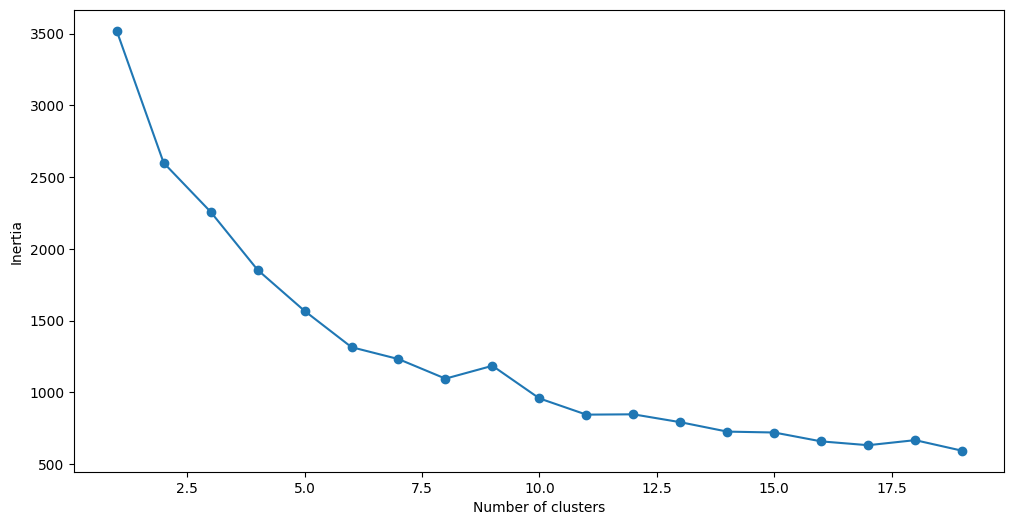

In [13]:
# fitting multiple k-means algorithms and storing the values in an empty list
SSE = []
for cluster in range(1,20):
    kmeans = KMeans(n_clusters = cluster, init='k-means++')
    kmeans.fit(data_scaled)
    SSE.append(kmeans.inertia_)

# converting the results into a dataframe and plotting them
frame = pd.DataFrame({'Cluster':range(1,20), 'SSE':SSE})
plt.figure(figsize=(12,6))
plt.plot(frame['Cluster'], frame['SSE'], marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')

Interpret the result of the elbow curve.

The elbow curve shows the number of clusters on the x-axis and the inertia (SSE) on the y-axis. As the number of clusters increases from 1 to 19, the inertia keeps dropping because the data points end up closer to a center. We look for the "elbow point" on the graph, the spot where the line bends sharply and starts to flatten out. That point marks the best number of clusters because it gives us compact groups without creating too many unnecessary clusters.

Build a model using 5 clusters and k-means ++ initialization

In [15]:
# k means using 5 clusters and k-means++ initialization
kmeans = KMeans(n_clusters = 5, init='k-means++')
kmeans.fit(data_scaled)
pred = kmeans.predict(data_scaled)

In [16]:
frame = pd.DataFrame(data_scaled)
frame['cluster'] = pred
frame['cluster'].value_counts()

,count
cluster,
1,290
2,106
3,30
0,9
4,5


There are 208 data points belonging to cluster 1 (index 1), then 125 points in cluster 2 (index 2), and so on.

Compute the centroids of the K means cluster

In [17]:
centroids = kmeans.cluster_centers_
print(centroids)

[[-0.45263612  0.44700104  2.68499221  1.37119106  0.58094108  3.96208014
  -0.16463196  3.93806373]
 [-0.69029709 -0.05583432  0.04059627 -0.35503564 -0.44475939  0.0218387
  -0.44499565 -0.14358711]
 [ 1.44865163  0.18812893 -0.24389244  0.20684478  0.36743919 -0.31282015
   0.37151359 -0.00734204]
 [ 1.44865163 -0.31443536 -0.51563557  1.43828289  1.88705378 -0.27945052
   2.09019341  0.16248227]
 [ 1.44865163  0.33206724  1.07676383  5.1091166   5.63831714 -0.08989854
   5.68883695  0.42029528]]


What is the purpose of the centroids?

Centroids are the middle points or averages of each cluster. They serve as a snapshot of each customer segment by showing the average spending habits for that group. They also help assign new data points to a group by seeing which centroid is closest, and they tell the K-Means algorithm when to stop running once the center points stop moving.

Fit an agglomerative clustering model with two clusters.

In [18]:
from sklearn.cluster import AgglomerativeClustering

ag = AgglomerativeClustering(n_clusters=2, linkage='ward', compute_full_tree=True)
ag = ag.fit(data_scaled)
df['agglom'] = ag.fit_predict(data_scaled)

Visualize the dendrogram produced by agglomerative clustering

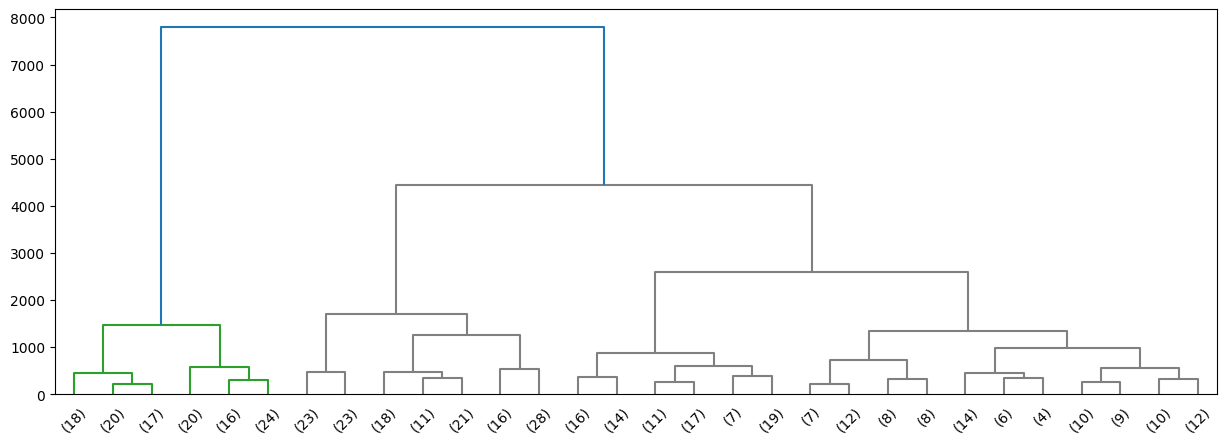

In [19]:
from scipy.cluster import hierarchy
from matplotlib import colors
import seaborn as sns

Z = hierarchy.linkage(ag.children_, method='ward')

fig, ax = plt.subplots(figsize=(15,5))

# Some color customization
dark_palette = sns.color_palette()
red = colors.to_hex(dark_palette[2])
blue = colors.to_hex(dark_palette[0])

hierarchy.set_link_color_palette([red, 'gray'])

den = hierarchy.dendrogram(Z, orientation='top',
                           p=30, truncate_mode='lastp',
                           show_leaf_counts=True, ax=ax,
                           above_threshold_color=blue)

Interpret the result of the dendogram

The dendrogram is a tree diagram that shows how data points get merged together step-by-step in Agglomerative Clustering. The vertical height on the chart shows how different two groups were before joining together. To pick the best number of clusters, we look for the longest vertical lines that are not crossed by any horizontal lines. The bottom branches group the most similar customer spending patterns, while the top branches show the largest differences across the dataset.Type your answer here

Supplementary Activity:
* Choose your own dataset.
* Import the dataset
* Determine the number of datapoints, columns and data types
* Remove unneccesary columns
* Do data cleaning such as removing empty values(NaN), replacing missing data .
* Standardize the variables.
* Perform descriptive statistics such as mean, median and mode
* Perform data visualization
* Use k-means clustering to identify the groups of the dataset.
* Use 1 to 10 clusters
* Determine the optimum number of clusters
* Use agglomerative clustering and visualize the dendogram
* Compare the results obtained by the K means and agglomerative clustering.

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster import hierarchy


df_supp = pd.read_csv("piracydataset.csv")
df_supp.head()


print("Shape of dataset:", df_supp.shape)
print("\nData Types:")
print(df_supp.dtypes)


df_supp = df_supp.drop(columns=['Unnamed: 0', 'discordid', 'minecraftid'])


print("\nMissing values check:")
print(df_supp.isnull().sum())
df_supp = df_supp.dropna()

df_encoded = pd.get_dummies(df_supp, columns=['client', 'version'], drop_first=True, dtype=int)


print("\nMean:")
print(df_encoded.mean())

print("\nMedian:")
print(df_encoded.median())

print("\nMode:")
print(df_encoded.mode().iloc[0])

Shape of dataset: (1423, 6)

Data Types:
Unnamed: 0       int64
age            float64
discordid       object
minecraftid     object
client          object
version         object
dtype: object

Missing values check:
age        1
client     0
version    0
dtype: int64

Mean:
age                                  16.740506
client_Mobile ( bedrock version )     0.185654
version_Paid Version                  0.187764
dtype: float64

Median:
age                                  16.0
client_Mobile ( bedrock version )     0.0
version_Paid Version                  0.0
dtype: float64

Mode:
age                                  17.0
client_Mobile ( bedrock version )     0.0
version_Paid Version                  0.0
Name: 0, dtype: float64


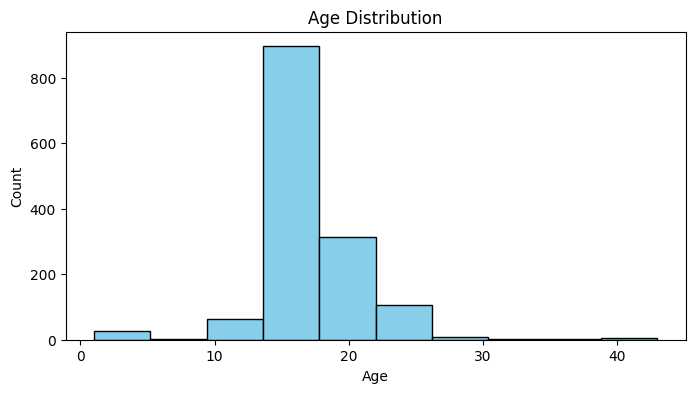

In [33]:
# Plot histogram for player age distribution
plt.figure(figsize=(8, 4))
plt.hist(df_encoded['age'], color='skyblue', edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

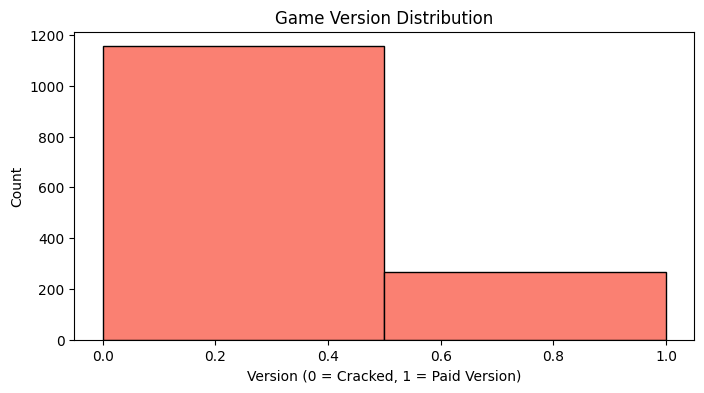

In [34]:
# Plot distribution for game version (0 = Cracked, 1 = Paid Version)
plt.figure(figsize=(8, 4))
plt.hist(df_encoded['version_Paid Version'], color='salmon', edgecolor='black', bins=2)
plt.title('Game Version Distribution')
plt.xlabel('Version (0 = Cracked, 1 = Paid Version)')
plt.ylabel('Count')
plt.show()

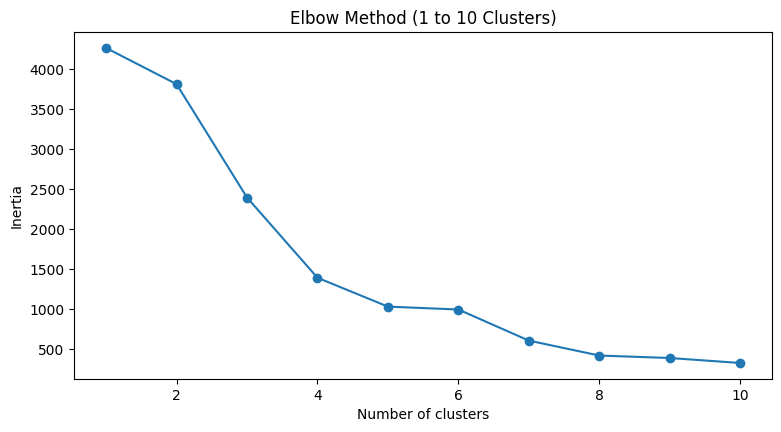

In [35]:
# Standardize variables using StandardScaler
scaler = StandardScaler()
data_scaled_supp = scaler.fit_transform(df_encoded)

# Fitting multiple k-means algorithms (1 to 10 clusters) and storing SSE
SSE_supp = []
for cluster in range(1, 11):
    kmeans = KMeans(n_clusters=cluster, init='k-means++', random_state=42)
    kmeans.fit(data_scaled_supp)
    SSE_supp.append(kmeans.inertia_)

# Plot the elbow curve to determine optimal number of clusters
frame_supp = pd.DataFrame({'Cluster': range(1, 11), 'SSE': SSE_supp})
plt.figure(figsize=(9, 4.5))
plt.plot(frame_supp['Cluster'], frame_supp['SSE'], marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method (1 to 10 Clusters)')
plt.show()

Cluster Centroids:
[[-3.90752603  0.14331636 -0.03930602]
 [ 0.05056746 -0.47747175 -0.4808002 ]
 [ 0.13925425  2.09436473  0.31629435]
 [ 0.16092613 -0.47747175  2.07986603]]


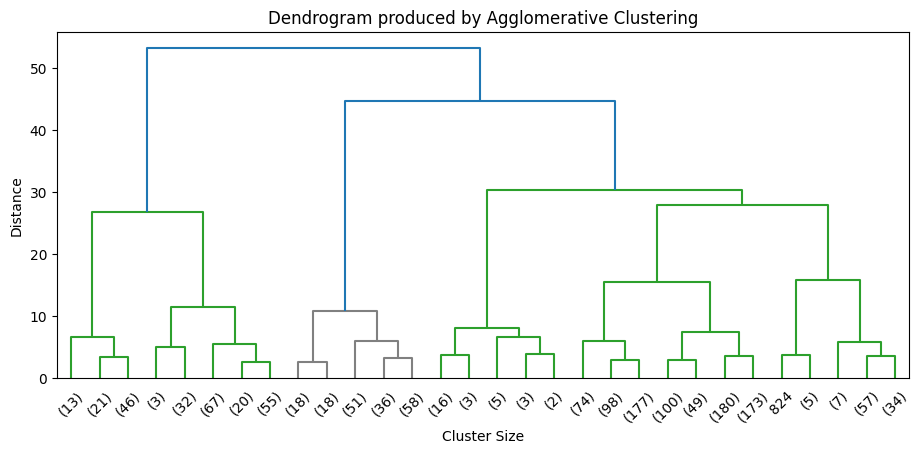

In [36]:
# Build optimal K-Means model using 4 clusters
kmeans = KMeans(n_clusters=4, init='k-means++', random_state=42)
pred_supp = kmeans.fit_predict(data_scaled_supp)

# Print centroids
print("Cluster Centroids:")
print(kmeans.cluster_centers_)

# Fit an agglomerative clustering model with 4 clusters
ag = AgglomerativeClustering(n_clusters=4, linkage='ward')
df_supp['agglom'] = ag.fit_predict(data_scaled_supp)

# Visualize the dendrogram produced by agglomerative clustering
Z = hierarchy.linkage(data_scaled_supp, method='ward')
fig, ax = plt.subplots(figsize=(11, 4.5))
den = hierarchy.dendrogram(Z, orientation='top', p=30, truncate_mode='lastp', ax=ax)
plt.title('Dendrogram produced by Agglomerative Clustering')
plt.xlabel('Cluster Size')
plt.ylabel('Distance')
plt.show()

Both K-Means and Agglomerative Clustering were able to identify clear groups in the dataset based on player age, client type, and game version. K-Means grouped the data points quickly by measuring distance to central points, which made it easy to assign each player to a distinct group. Agglomerative Clustering organized the dataset hierarchically from the bottom up, creating a dendrogram that showed how individual data points gradually merged into larger categories. The elbow plot in K-Means showed a distinct drop and flattening around 4 clusters, which lined up with the four primary main branches seen near the top of the dendrogram. Overall, K-Means was faster and simpler for defining flat groups, while Agglomerative Clustering provided better visual detail on how subgroups connected to one another.

#### Conclusion

In this lab, we used K-Means and Agglomerative Clustering to group customer spending data. Standardizing the features using StandardScaler was a necessary step so columns with large numbers would not dominate the distance calculations. Using the elbow plot for K-Means and the dendrogram for Agglomerative Clustering helped us visually figure out the right number of clusters. Overall, K-Means was quick and effective for making distinct groups, while Agglomerative Clustering gave a clear picture of how those groups relate to each other hierarchically.Type your answer here